In [1]:
!pip install -q transformers pyspark
import pandas as pd
df = pd.read_csv("results.csv")
print(df.shape)
print(df[["brand", "source", "language", "label"]].head())


(881, 14)
    brand       source language     label
0  Borjan  google_maps  english  positive
1  Borjan  google_maps  english  positive
2  Borjan  google_maps  english  positive
3  Borjan  google_maps  english  positive
4  Borjan  google_maps  english  positive


In [2]:
from transformers import pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
from google.colab import files

clf = pipeline("sentiment-analysis",
               model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
               device=0, truncation=True, max_length=128)

texts = df["clean_text"].fillna("").tolist()
out = clf(texts, batch_size=32)
df["bert_pred"] = [o["label"].lower() for o in out]

print(df["bert_pred"].value_counts(), "\n")

lab = df[df["label"].notna()]
print("Pretrained model vs star labels")
print("Accuracy:", round(accuracy_score(lab["label"], lab["bert_pred"]), 3))
print("Macro F1:", round(f1_score(lab["label"], lab["bert_pred"], average="macro"), 3))
print(classification_report(lab["label"], lab["bert_pred"]))

df.to_csv("results_bert.csv", index=False, encoding="utf-8-sig")
files.download("results_bert.csv")

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

bert_pred
neutral     376
positive    305
negative    200
Name: count, dtype: int64 

Pretrained model vs star labels
Accuracy: 0.552
Macro F1: 0.488
              precision    recall  f1-score   support

    negative       0.48      0.75      0.59        53
     neutral       0.22      0.17      0.19        46
    positive       0.77      0.62      0.68       104

    accuracy                           0.55       203
   macro avg       0.49      0.51      0.49       203
weighted avg       0.57      0.55      0.55       203



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

bert_pred           negative  neutral  positive
brand  source                                  
Borjan google_maps      34.0     12.6      53.4
       youtube          22.7     38.6      38.6
Ndure  google_maps      48.0     24.0      28.0
       youtube          20.7     37.9      41.4
Servis youtube          16.5     52.1      31.4

brand   source     
Borjan  google_maps    103
        youtube         44
Ndure   google_maps    100
        youtube         58
Servis  youtube        576
dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

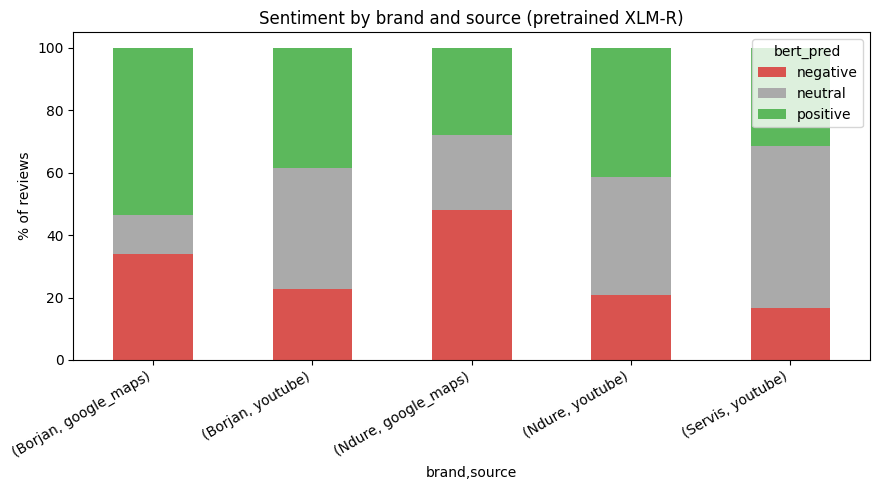

In [3]:
import matplotlib.pyplot as plt
order = ["negative", "neutral", "positive"]
pivot = (pd.crosstab([df["brand"], df["source"]], df["bert_pred"],
                     normalize="index") * 100).reindex(columns=order, fill_value=0)
print(pivot.round(1))
print()
print(df.groupby(["brand", "source"]).size())

pivot.plot(kind="bar", stacked=True, figsize=(9, 5),
           color=["#d9534f", "#aaaaaa", "#5cb85c"])
plt.ylabel("% of reviews")
plt.title("Sentiment by brand and source (pretrained XLM-R)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("sentiment_by_brand_bert.png", dpi=150)
files.download("sentiment_by_brand_bert.png")

In [4]:
import time
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.master("local[*]").appName("bench").getOrCreate()
base = df[["brand", "source", "clean_text", "bert_pred"]].fillna("")
base_sdf = spark.createDataFrame(base)

def pandas_job(p):
    t = p["clean_text"].str.lower().str.replace(r"[^\w\s]", " ", regex=True)
    p = p.assign(n_words=t.str.split().str.len())
    return p.groupby(["brand", "source", "bert_pred"]).agg(
        n=("n_words", "size"), avg_words=("n_words", "mean"))

def spark_job(s):
    t = F.regexp_replace(F.lower(F.col("clean_text")), r"[^\w\s]", " ")
    s = s.withColumn("n_words", F.size(F.split(F.trim(t), r"\s+")))
    return (s.groupBy("brand", "source", "bert_pred")
             .agg(F.count("*").alias("n"), F.avg("n_words").alias("avg_words"))
             .collect())

spark_job(base_sdf)  # warm-up so Spark startup isn't counted

rows = []
for k in [1, 100, 1000, 4000]:
    p = pd.concat([base] * k, ignore_index=True)
    s = base_sdf.crossJoin(spark.range(k)).drop("id").cache()
    n = s.count()  # materialise outside the timer

    t0 = time.time(); pandas_job(p); tp = time.time() - t0
    t0 = time.time(); spark_job(s);  ts = time.time() - t0
    rows.append({"rows": n, "pandas_sec": round(tp, 2), "spark_sec": round(ts, 2)})
    print(rows[-1])
    s.unpersist(); del p

bench = pd.DataFrame(rows)
print(bench)
bench.to_csv("benchmark.csv", index=False)
files.download("benchmark.csv")

{'rows': 881, 'pandas_sec': 0.03, 'spark_sec': 0.66}
{'rows': 88100, 'pandas_sec': 0.48, 'spark_sec': 1.5}
{'rows': 881000, 'pandas_sec': 4.59, 'spark_sec': 4.6}
{'rows': 3524000, 'pandas_sec': 16.54, 'spark_sec': 14.93}
      rows  pandas_sec  spark_sec
0      881        0.03       0.66
1    88100        0.48       1.50
2   881000        4.59       4.60
3  3524000       16.54      14.93


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>